In [2]:
# loading libraries for data manipulation
import numpy as np
import pandas as pd

# loading libraries for data visualization
import matplotlib.pyplot as plt
from plotnine import *

# import tensorflow and keras packages
import tensorflow as tf
from tensorflow import keras

import warnings
warnings.filterwarnings('ignore')

We will load the MNIST data again.

In [3]:
# Load MNIST data from keras.datasets
(X_train_mnist, y_train_mnist), (X_test_mnist, y_test_mnist) = keras.datasets.mnist.load_data()

X_train_mnist = X_train_mnist.reshape(-1, 28*28).astype('float32') / 255.0
X_test_mnist = X_test_mnist.reshape(-1, 28*28).astype('float32') / 255.0

# Convert y labels to one-hot encoded vectors
y_train_mnist = keras.utils.to_categorical(y_train_mnist, num_classes=10)
y_test_mnist = keras.utils.to_categorical(y_test_mnist, num_classes=10)



Let's first build a deep neural network to classify digits without any regularization

In [4]:
model = keras.Sequential([
        keras.layers.Dense(256,activation='relu',input_shape=(784,)),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(256,activation='relu'),
        keras.layers.Dropout(0.2),
        keras.layers.Dense(10,activation='softmax') # output layer
    ])

model.compile(loss="categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])

model.fit(X_train_mnist,y_train_mnist,
                           epochs=5,verbose=1,batch_size=128,
                           validation_data=(X_test_mnist,y_test_mnist))

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9061 - loss: 0.3129 - val_accuracy: 0.9581 - val_loss: 0.1342
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9602 - loss: 0.1310 - val_accuracy: 0.9693 - val_loss: 0.0975
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9708 - loss: 0.0930 - val_accuracy: 0.9761 - val_loss: 0.0755
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9768 - loss: 0.0740 - val_accuracy: 0.9775 - val_loss: 0.0742
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9805 - loss: 0.0617 - val_accuracy: 0.9781 - val_loss: 0.0694


This is a feed forward fully connected neural network. That is, there is a forward pass and a backward pass but all nodes in one layer are connected to all nodes in the next layer. This mechanism is not able to capture any spatial properties in the input data. 

Now let's train a Convolutional Neural Network. 

First we will reload our input data but now in the form of images. We will keep the 28x28 shape of the inputs. Note that the 1 in 28x28x1 indicates the number of channels. Here it is one to indicate grayscale images. 

In [5]:
(X_train_mnist, y_train_mnist), (X_test_mnist, y_test_mnist) = keras.datasets.mnist.load_data()

X_train_mnist = X_train_mnist.reshape(-1, 28,28,1).astype('float32') / 255.0
X_test_mnist = X_test_mnist.reshape(-1, 28,28,1).astype('float32') / 255.0

# Convert y labels to one-hot encoded vectors
y_train_mnist = keras.utils.to_categorical(y_train_mnist, num_classes=10)
y_test_mnist = keras.utils.to_categorical(y_test_mnist, num_classes=10)

There are some new layers to get familiar with. 

- Conv2D - convolution layer with filter size, number of filters, stride, and padding
- max pooling layer with pool size and stride

In [6]:
model = keras.Sequential([

    # Input: grayscale images with shape (28, 28, 1)
    # First convolution extracts low-level features from the image
    keras.layers.Conv2D(
        32, # 32 distinct image filters/kernels
        (3, 3), # filter size is 3 by 3
        activation="relu", # activation applied to the weighted sum
        input_shape=(28, 28, 1) # represents 28x28 images in 1 channel (greyscale)
    ),

    # Reduce spatial dimensions while retaining the important features
    keras.layers.MaxPooling2D((2, 2)),

    # Further extract higher-level features
    keras.layers.Conv2D(64, (3, 3), activation="relu"),

    # Reduce the feature map size again
    keras.layers.MaxPooling2D((2, 2)),

    # Convert the convolutional feature maps into a 1D vector
    keras.layers.Flatten(),

    # Dense layer learns complex feature combinations
    keras.layers.Dense(64, activation="relu"),

    # Output layer predicts probabilities for each digit class
    keras.layers.Dense(10, activation="softmax")
])

model.compile(loss="categorical_crossentropy",
              optimizer="adam", #keras.optimizers.SGD(0.01)
              metrics=["accuracy"])

model.fit(X_train_mnist,y_train_mnist,
                           epochs=5,verbose=1,batch_size=128,
                           validation_data=(X_test_mnist,y_test_mnist))

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9321 - loss: 0.2434 - val_accuracy: 0.9792 - val_loss: 0.0652
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9809 - loss: 0.0638 - val_accuracy: 0.9868 - val_loss: 0.0430
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9864 - loss: 0.0449 - val_accuracy: 0.9879 - val_loss: 0.0343
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9894 - loss: 0.0344 - val_accuracy: 0.9883 - val_loss: 0.0345
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9911 - loss: 0.0287 - val_accuracy: 0.9875 - val_loss: 0.0363


The model summary will show that there are now stacks of filters being used in the convolution layers, which are then pooled together to further reduce, in the max pooling layers. Note that there are no additional parameters to learn from the pooling layers. 

In [7]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 365,792 (1.40 MB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 243,862 (952.59 KB)

Let's modify the padding and stride values. 

- Larger stride values reduces spatial resolution: feature map shrinks faster
- Also speeds up training but the network might miss finer details

- padding = "same" retains spatial dimensions, helps detect objects touching the boundaries
- Also means you can stack more layers in the network without shrinking features maps too much

- padding = "valid" means no padding: reduces feature map dimensions
- Faster but loses edge information

In [10]:
model = keras.Sequential([
    keras.layers.Conv2D(32,(3,3),strides=(2,2),padding="valid",activation="relu",input_shape=(28,28,1)),
    keras.layers.MaxPooling2D(pool_size=(2,2),strides=(2,2),padding="valid"),
    keras.layers.Conv2D(64,(3,3),strides=(1,1),padding="valid",activation="relu"),
    keras.layers.MaxPooling2D(pool_size=(2,2),strides=(2,2),padding="valid"),
    keras.layers.Flatten(),
    keras.layers.Dense(64,activation="relu"),
    keras.layers.Dense(10,activation="softmax")
    ])

model.compile(loss="categorical_crossentropy",
              optimizer="adam", #keras.optimizers.SGD(0.01)
              metrics=["accuracy"])

model.fit(X_train_mnist,y_train_mnist,
                           epochs=5,verbose=1,batch_size=128,
                           validation_data=(X_test_mnist,y_test_mnist))

Epoch 1/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8911 - loss: 0.3897 - val_accuracy: 0.9628 - val_loss: 0.1172
Epoch 2/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9672 - loss: 0.1084 - val_accuracy: 0.9737 - val_loss: 0.0818
Epoch 3/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9751 - loss: 0.0803 - val_accuracy: 0.9749 - val_loss: 0.0808
Epoch 4/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9805 - loss: 0.0638 - val_accuracy: 0.9726 - val_loss: 0.0810
Epoch 5/5
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9820 - loss: 0.0570 - val_accuracy: 0.9822 - val_loss: 0.0581


In [11]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 13, 13, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 107,744 (420.88 KB)

 Trainable params: 35,914 (140.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 71,830 (280.59 KB)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 525us/step


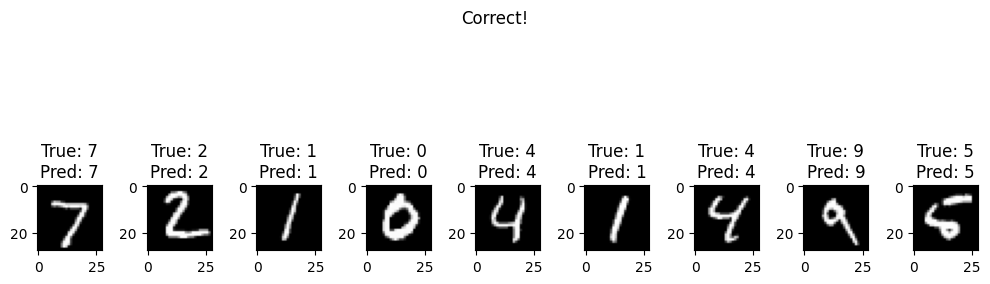

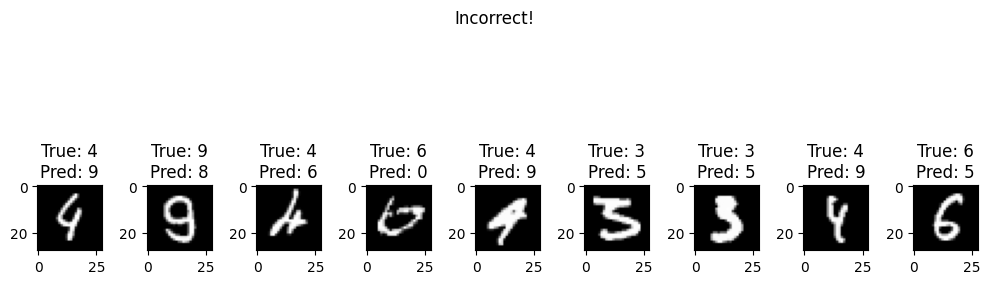

In [12]:

# predict on test data to identify correct and incorrect classifications
y_pred_probs = model.predict(X_test_mnist)
y_pred = np.argmax(y_pred_probs, axis=1)  # predicted classes
y_true = np.argmax(y_test_mnist, axis=1)  # actual classes

# separate correct and incorrect predictions
correct_indices = np.where(y_pred == y_true)[0]
incorrect_indices = np.where(y_pred != y_true)[0]

# display up to 9 predictions in each case
def show_images(indices, title, n=9):
    plt.figure(figsize=(10, 4))
    for i, idx in enumerate(indices[:n]):
        plt.subplot(1, n, i + 1)
        plt.imshow(X_test_mnist[idx].reshape(28, 28), cmap='gray')
        plt.title(f"True: {y_true[idx]}\nPred: {y_pred[idx]}")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_images(correct_indices, "Correct!")
show_images(incorrect_indices, "Incorrect!")
